In [1]:
import pandas as pd

In [2]:
!pip install pyarrow

In [13]:
import datetime as dt
from sklearn.feature_extraction import DictVectorizer

In [65]:
import seaborn as sns
import matplotlib.pyplot as plt

In [121]:
train_df = pd.read_parquet('data/yellow_tripdata_2021-02.parquet')

In [122]:
# train_df.columns

In [123]:
val_df = pd.read_parquet('data/yellow_tripdata_2021-02.parquet')

In [124]:
val_df = val_df.rename(columns={'tpep_pickup_datetime': 'pickup_datetime', 'tpep_dropoff_datetime': 'dropoff_datetime'})

In [125]:
train_df = train_df.rename(columns={'tpep_pickup_datetime': 'pickup_datetime', 'tpep_dropoff_datetime': 'dropoff_datetime'})

In [126]:
def inferance(df):
    df['duration'] = (df['dropoff_datetime']- df['pickup_datetime']).dt.total_seconds()/60
    df = df[(df.duration >= 1) & (df.duration >= 60)]
    
    return df

In [127]:
train_df = inferance(train_df)



In [128]:
# train_df



In [129]:
val_df = inferance(val_df)

In [146]:
# categorical = ['PULocationID','DOLocationID']
# numerical = ['trip_distance']


categorical_value = ['PULocationID','DOLocationID']
numerical = ['trip_distance']
train_df[categorical_value] = train_df[categorical_value].astype(str)

train_df['PU_DO'] = train_df['PULocationID'] + '_' + train_df['DOLocationID']

categorical = ['PU_DO'] 
# numerical = ['trip_distance']

train_dicts = train_df[categorical+numerical].to_dict(orient = 'records')
dv = DictVectorizer()

X_train = dv.fit_transform(train_dicts)

target = 'duration'

Y_train = train_df[target].values


In [147]:
# categorical = ['PULocationID','DOLocationID']
# numerical = ['trip_distance']

val_df[categorical_value] = val_df[categorical_value].astype(str)

val_df ['PU_DO'] = val_df ['PULocationID'] + '_' + val_df ['DOLocationID']
val_dicts = val_df[categorical+numerical].to_dict(orient = 'records')
# dv = DictVectorizer()

X_val = dv.transform(val_dicts)
Y_val = val_df[target].values

In [148]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

model = LinearRegression()

model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5057,)","[-324.71,-349.59,-378.42,...,-385.31,-336.5 , 0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,407.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5057


In [149]:
y_pred = model.predict(X_val)

In [150]:
rmse = root_mean_squared_error(Y_val,y_pred)

In [151]:
rmse

216.91246617869817

/tmp/ipykernel_4988/4293836138.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_pred, label='prediction')
/tmp/ipykernel_4988/4293836138.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(Y_val, label='actual')


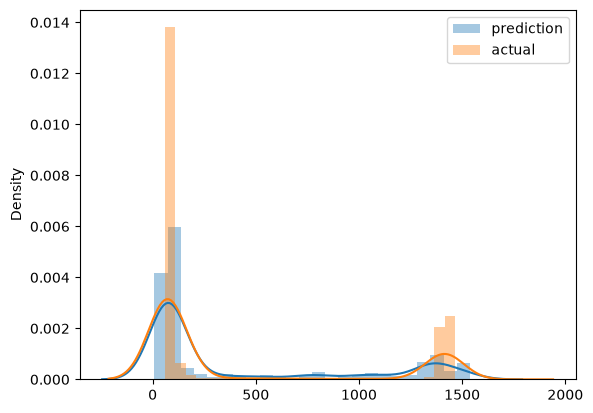

In [152]:
sns.distplot(y_pred, label='prediction')
sns.distplot(Y_val, label='actual')

plt.legend()

In [153]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge

In [156]:
import numpy as np
from scipy import sparse

def to_int32(X):
    X = sparse.csc_matrix(X)          # Lasso works on CSC internally
    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)
    return X

X_train = to_int32(X_train)
X_val = to_int32(X_val)



lr = Lasso(0.01)
lr.fit(X_train, Y_train)

y_pred = lr.predict(X_val)

root_mean_squared_error(Y_val, y_pred)

216.9898679834695